# RF-DETR tank detector


Dataset format:
```
tank-dataset/
  train/  images + _annotations.coco.json
  valid/  images + _annotations.coco.json
```

## 1. Setup
Run this cell again first if you ever restart the session; every section below only needs these values and the checkpoint on disk.

In [1]:
!pip install -q --no-warn-conflicts \
  "timm>=1.0.27,<2" \
  "rfdetr[train,onnx,loggers] @ git+https://github.com/roboflow/rf-detr@develop" \
  "git+https://github.com/roboflow/rf-detr_plus@feat/pe-core-t-atto-femto-pico" \
  onnxconverter-common supervision

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, glob, shutil

# ---- EDIT THESE ----
DATASET_DIR = "/kaggle/input/datasets/jonzuka/tank-dataset"   # contains train/ and valid/
EPOCHS, BATCH = 3, 8
# --------------------

OUT = "/kaggle/working/rfdetr_out"                # training output
EXPORT = "/kaggle/working/export"                 # exported models
CKPT = f"{OUT}/checkpoint_best_total.pth"         # best checkpoint (name checked in section 3)
os.makedirs(EXPORT, exist_ok=True)

## 2. Visualize dataset

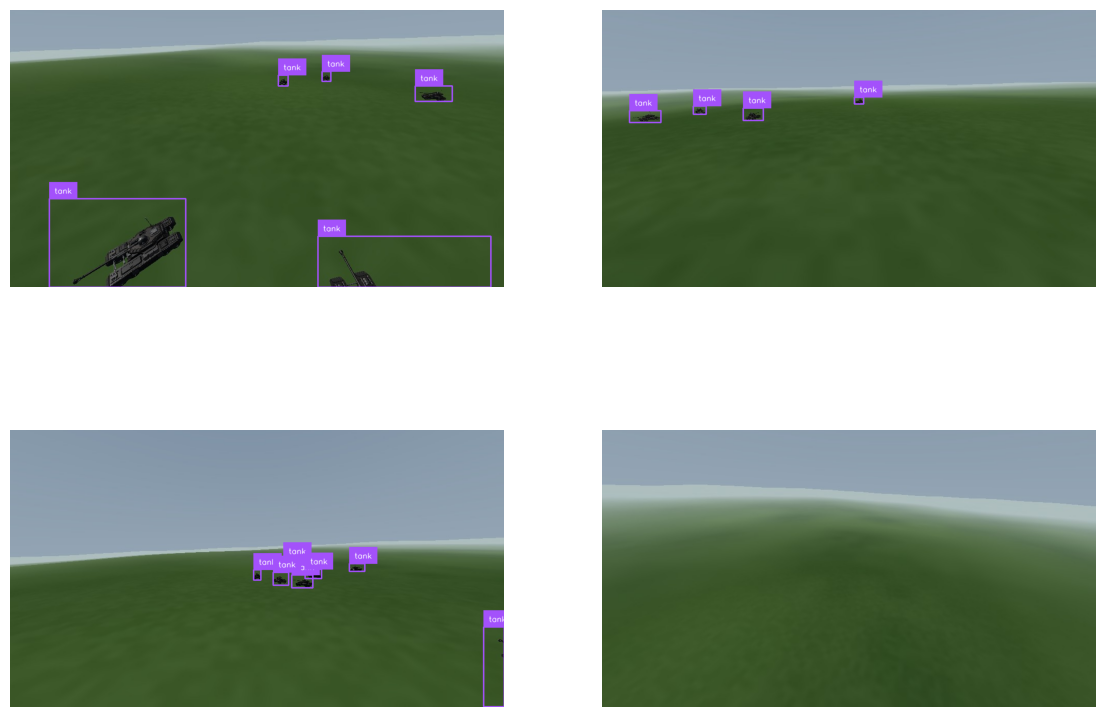

In [3]:
import random
import supervision as sv

ds = sv.DetectionDataset.from_coco(f"{DATASET_DIR}/train", f"{DATASET_DIR}/train/_annotations.coco.json")

box, label = sv.BoxAnnotator(), sv.LabelAnnotator()
grid = []
for i in random.Random(42).sample(range(len(ds)), 4):    # fixed seed: same 4 images every run
    _, image, det = ds[i]
    grid.append(label.annotate(box.annotate(image.copy(), det), det, [ds.classes[c] for c in det.class_id]))
sv.plot_images_grid(grid, grid_size=(2, 2), size=(14, 10))

## 3. Train
RF-DETR Nano is Apache-2.0 and starts from COCO weights. Metrics (COCO mAP) are printed during training.

If training fails because the dataset folder is read-only, copy it first: `shutil.copytree(DATASET_DIR, "/kaggle/working/dataset")` and point `DATASET_DIR` there.

In [4]:
from rfdetr_plus import RFDETRFemto

model = RFDETRFemto() 
model.train(dataset_dir=DATASET_DIR, epochs=EPOCHS, batch_size=BATCH, lr=1e-4, output_dir=OUT)

[2026-10-24 18:26:33] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-femto.pth


/root/.roboflow/models/rf-detr-femto.pth:   0%|          | 0.00/30.4M [00:00<?, ?iB/s]

[2026-10-24 18:26:34] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-femto.pth
[2026-10-24 18:26:35] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-femto.pth already exists with correct MD5 hash.
[2026-10-24 18:26:36] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-femto.pth already exists with correct MD5 hash.


[2026-10-24 18:26:36] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 1. The detection head will be re-initialized to 1 classes.
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


[2026-10-24 18:26:53] [INFO] rf-detr - Building Roboflow train dataset with square resize at resolution 384
[2026-10-24 18:26:53] [INFO] rf-detr - Using multi-scale training with square resize and scales: [544]
[2026-10-24 18:26:53] [INFO] rf-detr - Built 1 Albumentations transforms from config
[2026-10-24 18:26:53] [INFO] rf-detr - Built 1 Albumentations transforms from config
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
[2026-10-24 18:26:53] [INFO] rf-detr - Building Roboflow val dataset with square resize at resolution 384
[2026-10-24 18:26:53] [INFO] rf-detr - Using multi-scale training with square resize and scales: [544]


...

[2026-10-24 18:27:14] [INFO] rf-detr - Skipping validation-loss computation: compute_val_loss='auto' found no scheduler or callback monitoring 'val/loss', so no 'val/loss' metric is logged this run. Set compute_val_loss=True to log it every validation epoch (for example to read the curve from metrics.csv, TensorBoard, or Weights & Biases).


Output()

[2026-10-24 18:27:17] [INFO] rf-detr - Best EMA metric improved to 0.4211 (epoch 0)
[2026-10-24 18:27:27] [INFO] rf-detr - Best EMA metric improved to 0.5056 (epoch 1)
[2026-10-24 18:27:38] [INFO] rf-detr - Best EMA metric improved to 0.5567 (epoch 2)


`Trainer.fit` stopped: `max_epochs=3` reached.


[2026-10-24 18:27:39] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.5567)


## 4. Evaluate model

[2026-10-24 18:27:39] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


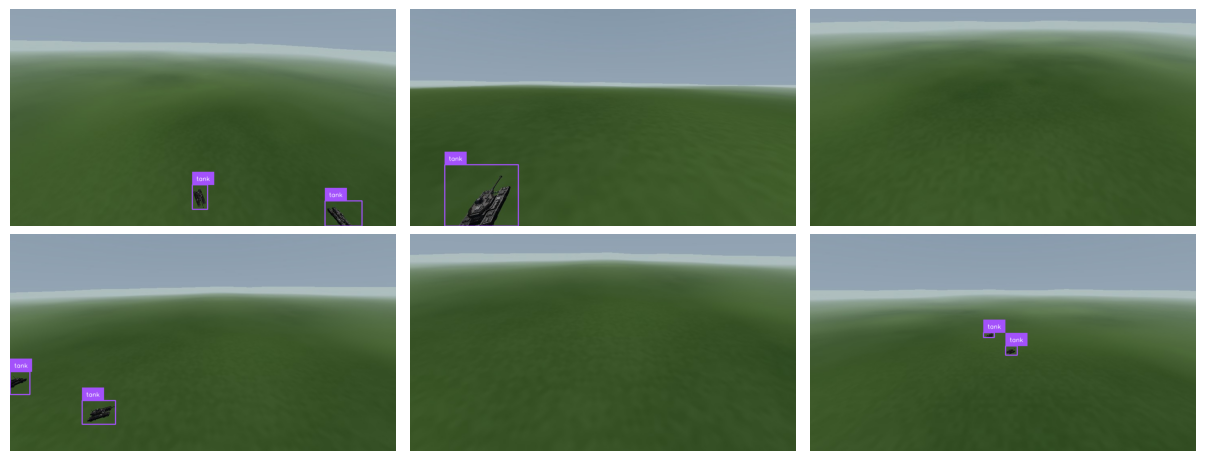

In [5]:
import supervision as sv
from PIL import Image
import matplotlib.pyplot as plt

model = RFDETRFemto(pretrain_weights=CKPT, num_classes=1)

img_paths = sorted(glob.glob(f"{DATASET_DIR}/valid/*.[jp][pn]g"))[:6]
images = [Image.open(p).convert("RGB") for p in img_paths]
detections = model.predict(images, threshold=0.5)

annotated = [
    sv.LabelAnnotator().annotate(
        sv.BoxAnnotator().annotate(image.copy(), det), det,
        [str(n) for n in det.data["class_name"]])
    for image, det in zip(images, detections)
]

cols = 3
rows = -(-len(annotated) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(12, 12 / cols * rows * images[0].height / images[0].width), layout="constrained")
for ax, img in zip(axes.flat, annotated):
    ax.imshow(img)
    ax.axis("off")
plt.show()


## 5. Export as ONNX
The fp16 copy keeps `GridSample` in fp32, because onnxruntime-web's fp16 `GridSample` on WebGPU is reported to return wrong boxes without any error. Compare fp16 and fp32 detections in the browser before trusting the fp16 file.

Send me the printed input and output names and shapes; the browser page needs them.

In [7]:
import onnxruntime as ort

model = RFDETRFemto(pretrain_weights=CKPT, num_classes=1)
model.export(format="onnx", output_dir=EXPORT)

[2026-10-24 18:31:11] [INFO] rf-detr - Exporting model to onnx format
[2026-10-24 18:31:14] [INFO] rf-detr - Successfully exported ONNX model to: /kaggle/working/export/rfdetr-femto.onnx


PosixPath('/kaggle/working/export/rfdetr-femto.onnx')

In [8]:
onnx_path = max(glob.glob(f"{EXPORT}/*.onnx"), key=os.path.getmtime) 
s = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
print(os.path.basename(onnx_path), f"{os.path.getsize(onnx_path) / 1e6:.0f} MB")
print([(i.name, i.shape) for i in s.get_inputs()], [(o.name, o.shape) for o in s.get_outputs()])

rfdetr-femto.onnx 41 MB
[('input', [1, 3, 384, 384])] [('dets', [1, 200, 4]), ('labels', [1, 200, 2])]


In [9]:
shutil.copy(CKPT, EXPORT)
shutil.make_archive("/kaggle/working/export", "zip", EXPORT)
print(os.listdir(EXPORT))

['checkpoint_best_total.pth', 'rfdetr-femto.onnx']
